# Policy Gradients: from REINFORCE to Actor-Critic (PyTorch)


## From value-based to policy-based

Policy-gradient methods learn the **policy itself**: a network $\pi_\theta(a \mid s)$ that outputs a probability for each action.
We then adjust $\theta$ to make good actions more likely.

The objective is the expected return, $J(\theta) = \mathbb{E}_{\tau \sim \pi_\theta}\big[R(\tau)\big]$. The
**policy gradient theorem**, via the "log-derivative trick" $\nabla_\theta \pi = \pi \, \nabla_\theta \log \pi$, gives

$$\nabla_\theta J(\theta) = \mathbb{E}_{\pi_\theta}\Big[\sum_t \nabla_\theta \log \pi_\theta(a_t \mid s_t)\; G_t\Big]$$

In words: raise the log-probability of each action **in proportion to the return that followed it**. This needs no
model of the environment and no `max` over actions. That is why policy gradients work naturally with stochastic
policies and continuous actions, where DQN struggles.

In code, we minimize the "surrogate loss" $\mathcal{L} = -\sum_t \log \pi_\theta(a_t \mid s_t)\, G_t$. Its gradient
*is* the policy gradient, so PyTorch's autograd does the rest.

| | DQN (dqn_deep_q) | Policy gradients (this notebook) |
|---|---|---|
| Learns | $Q(s,a)$, acts with argmax | $\pi(a \mid s)$ directly |
| Policy | deterministic (+ ε-greedy) | stochastic by design |
| Data | off-policy, replay buffer | **on-policy**: only fresh data from the current policy |
| Continuous actions | hard | easy (e.g. a Gaussian policy) |
| Main difficulty | instability (moving targets) | **high variance** of the gradient estimate |

Most of this notebook is about the last row: **reducing variance**.

In [3]:
# !pip install gymnasium torch matplotlib numpy imageio imageio-ffmpeg
# !pip install "gymnasium[box2d]"     # only for Part E (LunarLander); needs swig: `brew install swig` / `apt install swig`
import random
import time
from collections import deque
from dataclasses import dataclass, replace

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.distributions import Categorical

# Tiny networks and one-sample-at-a-time acting are faster on the CPU than on a GPU
device = torch.device("cpu")
print("gymnasium", gym.__version__, "| torch", torch.__version__)


def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

gymnasium 1.4.0 | torch 2.14.1


# Part A: REINFORCE (as in the Hugging Face course)

This follows the Unit 4 notebook closely, with two kinds of changes:
- **Gymnasium 1.x API:** `reset()` returns `(obs, info)`, and `step()` returns `terminated, truncated` instead of `done`.
- **The environment is passed in as an argument** instead of being a global variable.

### The policy network
A small MLP that ends in a **softmax**, so it outputs a probability for each action. `act()` **samples** an action
from those probabilities. Sampling is the exploration; there is no ε here.

In [4]:
env_id = "CartPole-v1"
env = gym.make(env_id)
eval_env = gym.make(env_id)

s_size = env.observation_space.shape[0]
a_size = env.action_space.n
print("observation size:", s_size, "| actions:", a_size)


class Policy(nn.Module):
    def __init__(self, s_size, a_size, h_size):
        super().__init__()
        self.fc1 = nn.Linear(s_size, h_size)
        self.fc2 = nn.Linear(h_size, a_size)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        return F.softmax(self.fc2(x), dim=1)

    def act(self, state):
        state = torch.from_numpy(state).float().unsqueeze(0).to(device)
        probs = self.forward(state).cpu()
        m = Categorical(probs)
        action = m.sample()
        return action.item(), m.log_prob(action)


# quick check
debug_policy = Policy(s_size, a_size, 16)
obs, _ = env.reset(seed=0)
print("action probabilities:", debug_policy(torch.from_numpy(obs).float().unsqueeze(0)).detach().numpy())
print("sampled action, log-prob:", debug_policy.act(obs))

observation size: 4 | actions: 2
action probabilities: [[0.49060866 0.50939137]]
sampled action, log-prob: (0, tensor([-0.7121], grad_fn=<SqueezeBackward1>))


### The REINFORCE algorithm

For each episode:
1. **Play** a full episode with the current policy, storing each `log_prob` and reward.
2. **Compute the return** $G_t$ for every step, backwards: $G_t = r_t + \gamma G_{t+1}$.
   This is the same backward pass as in Monte Carlo prediction (notebook 1).
3. **Standardize** the returns: subtract their mean and divide by their standard deviation. This trick from the course
   roughly centers the returns around zero, so above-average actions are pushed up and below-average ones are pushed
   down. It is a crude form of the **baseline** we build properly in Part B.
4. **Gradient step** on $-\sum_t \log \pi(a_t \mid s_t)\, G_t$.

Using $G_t$, the return from step *t* onward, instead of the whole episode's return is called **reward-to-go**.
An action can only affect rewards that come after it, so this removes noise without adding bias.

In [5]:
def reinforce(env, policy, optimizer, n_training_episodes, max_t, gamma, print_every):
    scores_deque = deque(maxlen=100)
    scores = []
    for i_episode in range(1, n_training_episodes + 1):
        saved_log_probs, rewards = [], []
        state, _ = env.reset()

        # 1) play one episode
        for t in range(max_t):
            action, log_prob = policy.act(state)
            saved_log_probs.append(log_prob)
            state, reward, terminated, truncated, _ = env.step(action)
            rewards.append(reward)
            if terminated or truncated:
                break
        scores_deque.append(sum(rewards))
        scores.append(sum(rewards))

        # 2) discounted returns G_t, computed backwards (reward-to-go)
        returns = deque(maxlen=max_t)
        n_steps = len(rewards)
        for t in range(n_steps)[::-1]:
            disc_return_t = returns[0] if len(returns) > 0 else 0
            returns.appendleft(gamma * disc_return_t + rewards[t])

        # 3) standardize the returns (more stable training)
        eps = np.finfo(np.float32).eps.item()
        returns = torch.tensor(returns)
        returns = (returns - returns.mean()) / (returns.std() + eps)

        # 4) policy gradient step: minimize -sum(log_prob * G_t)
        policy_loss = []
        for log_prob, disc_return in zip(saved_log_probs, returns):
            policy_loss.append(-log_prob * disc_return)
        policy_loss = torch.cat(policy_loss).sum()

        optimizer.zero_grad()
        policy_loss.backward()
        optimizer.step()

        if i_episode % print_every == 0:
            print(f"Episode {i_episode}\tAverage Score: {np.mean(scores_deque):.2f}")
    return scores

### Train
These are the course's CartPole hyperparameters. It uses γ = 1.0, which is fine because CartPole episodes are
capped at 500 steps. Training takes about 1–3 minutes on a CPU.

Episode 100	Average Score: 89.61
Episode 200	Average Score: 385.96
Episode 300	Average Score: 338.87
Episode 400	Average Score: 365.09
Episode 500	Average Score: 366.23
Episode 600	Average Score: 451.95
Episode 700	Average Score: 483.73
Episode 800	Average Score: 492.52
Episode 900	Average Score: 467.71
Episode 1000	Average Score: 489.66
trained in 31s


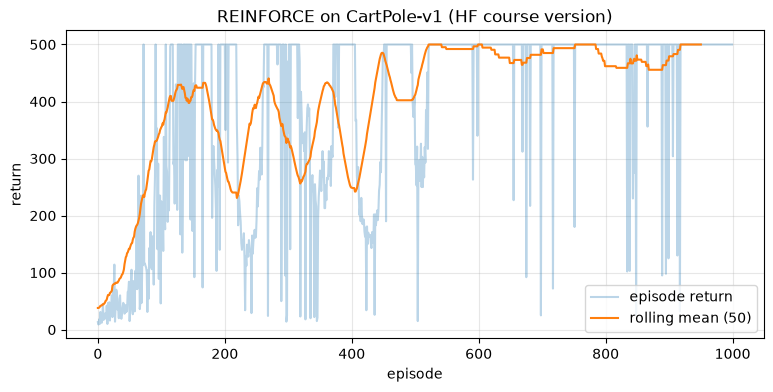

In [6]:
cartpole_hyperparameters = {
    "h_size": 16,
    "n_training_episodes": 1000,
    "n_evaluation_episodes": 10,
    "max_t": 1000,
    "gamma": 1.0,
    "lr": 1e-2,
    "env_id": env_id,
    "state_space": s_size,
    "action_space": a_size,
}

set_seed(0)
env.reset(seed=0)
cartpole_policy = Policy(cartpole_hyperparameters["state_space"], cartpole_hyperparameters["action_space"],
                         cartpole_hyperparameters["h_size"]).to(device)
cartpole_optimizer = optim.Adam(cartpole_policy.parameters(), lr=cartpole_hyperparameters["lr"])

t0 = time.time()
scores = reinforce(env, cartpole_policy, cartpole_optimizer,
                   cartpole_hyperparameters["n_training_episodes"], cartpole_hyperparameters["max_t"],
                   cartpole_hyperparameters["gamma"], print_every=100)
print(f"trained in {time.time() - t0:.0f}s")

plt.figure(figsize=(9, 4))
plt.plot(scores, alpha=.3, label="episode return")
plt.plot(np.convolve(scores, np.ones(50) / 50, mode="valid"), label="rolling mean (50)")
plt.xlabel("episode"); plt.ylabel("return"); plt.title("REINFORCE on CartPole-v1 (HF course version)")
plt.legend(); plt.grid(alpha=.3); plt.show()

### Evaluate
The course evaluates the **stochastic** policy, sampling actions just like in training. We also report the **greedy**
policy (argmax), which is often a bit better for a trained agent.

In [7]:
def evaluate_agent(env, max_steps, n_eval_episodes, policy, greedy=False, seed=1000):
    episode_rewards = []
    for episode in range(n_eval_episodes):
        state, _ = env.reset(seed=seed + episode)
        total_rewards_ep = 0
        for step in range(max_steps):
            if greedy:
                with torch.no_grad():
                    probs = policy(torch.from_numpy(state).float().unsqueeze(0).to(device))
                action = int(probs.argmax())
            else:
                action, _ = policy.act(state)
            state, reward, terminated, truncated, _ = env.step(action)
            total_rewards_ep += reward
            if terminated or truncated:
                break
        episode_rewards.append(total_rewards_ep)
    return np.mean(episode_rewards), np.std(episode_rewards)


for greedy in (False, True):
    mean_r, std_r = evaluate_agent(eval_env, cartpole_hyperparameters["max_t"],
                                   cartpole_hyperparameters["n_evaluation_episodes"], cartpole_policy, greedy=greedy)
    print(f"{'greedy' if greedy else 'stochastic':<10} policy: {mean_r:.1f} ± {std_r:.1f}")

stochastic policy: 500.0 ± 0.0
greedy     policy: 500.0 ± 0.0


**What to notice:** the learning curve is very **noisy**, and it often collapses after reaching 500 before recovering.
Run it with another seed and you will get a quite different curve. One episode gives a single, very noisy estimate of
the gradient. The rest of this notebook tackles that variance.

# Part B: REINFORCE, improved

Three classic changes, each of which keeps the gradient **unbiased** but makes it less noisy:

**1. Batch several episodes per update.** Averaging the gradient over *N* episodes reduces its variance by about a factor of *N*.

**2. A learned baseline, the "advantage".** We can subtract any function $b(s_t)$ that doesn't depend on the action:

$$\nabla_\theta J = \mathbb{E}\Big[\sum_t \nabla_\theta \log \pi_\theta(a_t \mid s_t)\,\big(G_t - b(s_t)\big)\Big]$$

This is still unbiased, because $\mathbb{E}_{a \sim \pi}\big[\nabla_\theta \log \pi_\theta(a \mid s)\big] = \nabla_\theta \sum_a \pi_\theta(a \mid s) = \nabla_\theta 1 = 0$.
The best simple choice is $b(s) \approx V(s)$, learned by a second network (the **critic**) by regressing onto $G_t$.
Then $A_t = G_t - V(s_t)$ asks *"was this action better or worse than usual **in this state**?"* The course's
standardization trick only asks "better or worse than the average step of this episode".

**3. Entropy bonus.** Add $\beta \cdot \mathcal{H}[\pi(\cdot \mid s)]$ to the objective. This discourages the policy
from becoming deterministic too early, which is one cause of the collapses seen in Part A.

We also switch to a cleaner implementation:
- The network outputs **logits**, and `Categorical(logits=...)` does the softmax internally, which is more numerically stable.
- Actions are sampled under `no_grad`, and log-probs are recomputed for the whole batch in **one** forward pass.
  This gives the same gradient as storing them, but it is faster and uses less memory.
- Progress is measured in **environment steps**, so methods can be compared fairly in Part D.

In [8]:
def layer_init(layer, std=np.sqrt(2), bias_const=0.0):
    '''Orthogonal init, standard for policy-gradient methods (as in CleanRL).'''
    nn.init.orthogonal_(layer.weight, std)
    nn.init.constant_(layer.bias, bias_const)
    return layer


class ActorCritic(nn.Module):
    '''Separate actor (policy logits) and critic (state value) networks.'''
    def __init__(self, obs_dim, n_actions, hidden=64):
        super().__init__()
        self.actor = nn.Sequential(
            layer_init(nn.Linear(obs_dim, hidden)), nn.Tanh(),
            layer_init(nn.Linear(hidden, hidden)), nn.Tanh(),
            layer_init(nn.Linear(hidden, n_actions), std=0.01),    # small: start close to a uniform policy
        )
        self.critic = nn.Sequential(
            layer_init(nn.Linear(obs_dim, hidden)), nn.Tanh(),
            layer_init(nn.Linear(hidden, hidden)), nn.Tanh(),
            layer_init(nn.Linear(hidden, 1), std=1.0),
        )

    def dist(self, x):
        return Categorical(logits=self.actor(x))

    def value(self, x):
        return self.critic(x).squeeze(-1)


def discounted_returns(rewards, gamma):
    '''Reward-to-go: G_t = r_t + gamma * G_{t+1}, computed backwards.'''
    G, out = 0.0, np.zeros(len(rewards), dtype=np.float32)
    for t in reversed(range(len(rewards))):
        G = rewards[t] + gamma * G
        out[t] = G
    return out

In [9]:
@dataclass
class PGConfig:
    env_id: str = "CartPole-v1"
    seed: int = 1
    total_steps: int = 150_000        # budget in environment steps
    gamma: float = 0.99
    lr: float = 3e-3
    hidden: int = 64
    episodes_per_update: int = 4      # 1. batching
    baseline: str = "value"           # 2. "none" | "normalize" (course trick) | "value" (learned critic)
    normalize_advantages: bool = True # standardize the advantages after subtracting the baseline
    entropy_coef: float = 0.01        # 3. entropy bonus
    value_coef: float = 0.5
    max_grad_norm: float = 0.5


def train_reinforce(cfg: PGConfig, verbose=True):
    set_seed(cfg.seed)
    env = gym.make(cfg.env_id)
    env.action_space.seed(cfg.seed)
    model = ActorCritic(env.observation_space.shape[0], env.action_space.n, cfg.hidden)
    optimizer = optim.Adam(model.parameters(), lr=cfg.lr)
    log = {"steps": [], "returns": []}
    total_steps, first_reset, n_updates = 0, True, 0

    while total_steps < cfg.total_steps:
        # ---- collect a batch of complete episodes with the CURRENT policy (on-policy!)
        b_obs, b_act, b_ret = [], [], []
        for _ in range(cfg.episodes_per_update):
            obs, _ = env.reset(seed=cfg.seed) if first_reset else env.reset()
            first_reset = False
            ep_rew, done = [], False
            while not done:
                with torch.no_grad():
                    action = model.dist(torch.as_tensor(obs, dtype=torch.float32)).sample().item()
                b_obs.append(obs); b_act.append(action)
                obs, reward, terminated, truncated, _ = env.step(action)
                ep_rew.append(reward)
                done = terminated or truncated
            total_steps += len(ep_rew)
            log["steps"].append(total_steps); log["returns"].append(sum(ep_rew))
            b_ret.append(discounted_returns(ep_rew, cfg.gamma))

        obs_t = torch.as_tensor(np.array(b_obs), dtype=torch.float32)
        act_t = torch.as_tensor(b_act)
        ret_t = torch.as_tensor(np.concatenate(b_ret))

        # ---- one forward pass for the whole batch
        dist = model.dist(obs_t)
        log_probs = dist.log_prob(act_t)
        entropy = dist.entropy().mean()

        if cfg.baseline == "value":
            values = model.value(obs_t)
            advantages = ret_t - values.detach()          # baseline: NO gradient through it into the policy
            value_loss = F.mse_loss(values, ret_t)        # the critic regresses onto the Monte Carlo returns
        else:
            advantages, value_loss = ret_t.clone(), torch.tensor(0.0)
        if (cfg.baseline == "normalize" or cfg.normalize_advantages) and cfg.baseline != "none" and len(advantages) > 1:
            advantages = (advantages - advantages.mean()) / (advantages.std() + 1e-8)

        # sum over time steps, mean over episodes (matches Part A when episodes_per_update = 1)
        policy_loss = -(log_probs * advantages).sum() / cfg.episodes_per_update
        loss = policy_loss + cfg.value_coef * value_loss - cfg.entropy_coef * entropy

        optimizer.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), cfg.max_grad_norm)
        optimizer.step()
        n_updates += 1

        if verbose and n_updates % 50 == 0:
            print(f"steps {total_steps:>7,} | avg return (last 20 ep) {np.mean(log['returns'][-20:]):6.1f} "
                  f"| entropy {entropy.item():.3f}")
    env.close()
    return model, log

### Configurations: from the course version to the full upgrade

- `course`: our re-implementation of Part A (1 episode per update, standardized returns, γ = 1, 16 hidden units, lr 1e-2).
- `+ batch`: 4 episodes per update.
- `+ baseline`: a learned critic $V(s)$.
- `+ entropy`: the full version.

Each gets the same budget of 150k environment steps. The cell below runs one seed per configuration; Part D repeats this
over several seeds.

course (Part A)    final avg return  457.9  (5s)
+ batch (4 ep)     final avg return  378.1  (5s)
+ value baseline   final avg return  482.4  (6s)
+ entropy (full)   final avg return  342.5  (6s)


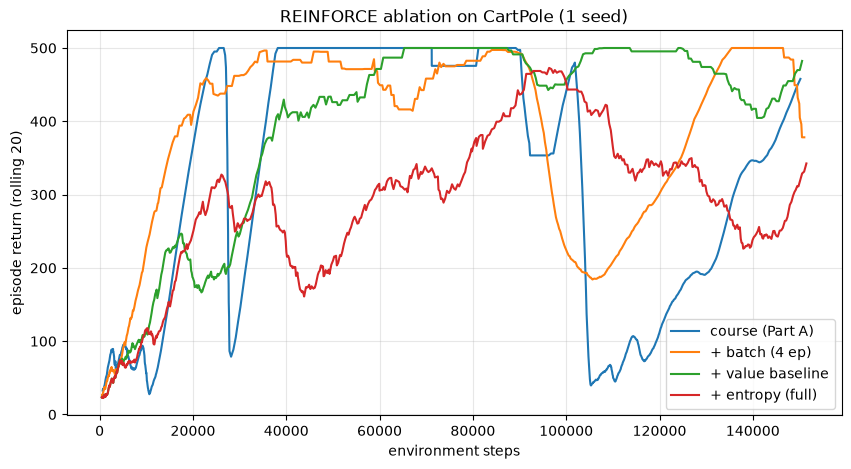

In [10]:
course_cfg = PGConfig(gamma=1.0, lr=1e-2, hidden=16, episodes_per_update=1, baseline="normalize",
                      normalize_advantages=False, entropy_coef=0.0, max_grad_norm=1e9)
reinforce_configs = {
    "course (Part A)": course_cfg,
    "+ batch (4 ep)": replace(course_cfg, episodes_per_update=4),
    "+ value baseline": replace(course_cfg, episodes_per_update=4, baseline="value", normalize_advantages=True,
                                gamma=0.99, hidden=64, lr=3e-3, max_grad_norm=0.5),
    "+ entropy (full)": PGConfig(),
}

def smooth(x, k=20):
    x = np.asarray(x)
    return np.convolve(x, np.ones(k) / k, mode="valid") if len(x) >= k else x

ablation_logs = {}
plt.figure(figsize=(10, 5))
for name, cfg in reinforce_configs.items():
    t0 = time.time()
    _, log = train_reinforce(cfg, verbose=False)
    ablation_logs[name] = log
    print(f"{name:<18} final avg return {np.mean(log['returns'][-20:]):6.1f}  ({time.time() - t0:.0f}s)")
    s = smooth(log["returns"])
    plt.plot(log["steps"][len(log["steps"]) - len(s):], s, label=name)
plt.xlabel("environment steps"); plt.ylabel("episode return (rolling 20)")
plt.title("REINFORCE ablation on CartPole (1 seed)"); plt.legend(); plt.grid(alpha=.3); plt.show()

With a single seed, don't over-interpret small differences. The typical pattern is that batching and the baseline
make the curve **smoother** and less prone to sudden collapses. Part D checks this properly over several seeds.

# Part C: Advantage Actor-Critic (A2C) with GAE

REINFORCE still has two weaknesses:
1. It must wait until an episode **ends** before learning anything, because it needs the full return $G_t$.
2. $G_t$ sums many random rewards, so it is noisy, even with a baseline.

**Actor-critic** methods replace $G_t$ with a **bootstrapped** estimate, exactly the step from Monte Carlo to TD
in notebook 1. The one-step TD error

$$\delta_t = r_t + \gamma V(s_{t+1}) - V(s_t)$$

is already an estimate of the advantage. **Generalized Advantage Estimation** (GAE, Schulman et al. 2016) blends
the *n*-step versions with a parameter λ, much like n-step TD blended TD(0) and MC in notebook 1:

$$\hat A_t = \sum_{l \ge 0} (\gamma \lambda)^l \, \delta_{t+l}$$

λ = 0 gives the one-step TD advantage: low variance, more bias. λ = 1 gives Monte Carlo minus a baseline, which is REINFORCE.
λ ≈ 0.95 is the usual sweet spot.

**A2C also runs several environments in parallel.** Each update uses `n_envs × n_steps` transitions from different
episodes, which decorrelates the data much as DQN's replay buffer does. Here the "parallel" environments are a plain
Python list, so we handle resets and **truncation** ourselves:
- When an episode is **truncated** (CartPole's 500-step limit), the state still had a future. So we add
  $\gamma V(s_{\text{final}})$ to the last reward, bootstrapping just as DQN did on truncation.
- When it **terminates**, the future is worth 0.

In [11]:
@dataclass
class A2CConfig:
    env_id: str = "CartPole-v1"
    seed: int = 1
    total_steps: int = 150_000
    n_envs: int = 8
    n_steps: int = 32              # rollout length per env per update -> 256 transitions per update
    gamma: float = 0.99
    gae_lambda: float = 0.95
    lr: float = 1e-3
    hidden: int = 64
    entropy_coef: float = 0.01
    value_coef: float = 0.5
    max_grad_norm: float = 0.5
    normalize_advantages: bool = True


def compute_gae(rewards, values, dones, next_value, gamma, lam):
    '''rewards, values, dones: arrays of shape (T, n_envs); dones[t] = 1 if the episode ended at step t.'''
    T = rewards.shape[0]
    advantages = np.zeros_like(rewards)
    last_gae = np.zeros(rewards.shape[1], dtype=np.float32)
    for t in reversed(range(T)):
        next_v = next_value if t == T - 1 else values[t + 1]
        not_done = 1.0 - dones[t]
        delta = rewards[t] + gamma * next_v * not_done - values[t]      # TD error
        last_gae = delta + gamma * lam * not_done * last_gae             # discounted sum of TD errors
        advantages[t] = last_gae
    returns = advantages + values                                        # targets for the critic
    return advantages, returns


def train_a2c(cfg: A2CConfig, verbose=True):
    set_seed(cfg.seed)
    envs = [gym.make(cfg.env_id) for _ in range(cfg.n_envs)]
    for i, e in enumerate(envs):
        e.action_space.seed(cfg.seed + i)
    obs_dim, n_actions = envs[0].observation_space.shape[0], envs[0].action_space.n
    model = ActorCritic(obs_dim, n_actions, cfg.hidden)
    optimizer = optim.Adam(model.parameters(), lr=cfg.lr, eps=1e-5)

    obs = np.stack([e.reset(seed=cfg.seed + i)[0] for i, e in enumerate(envs)]).astype(np.float32)
    ep_return = np.zeros(cfg.n_envs)
    log = {"steps": [], "returns": []}
    total_steps, n_updates = 0, 0
    T, K = cfg.n_steps, cfg.n_envs

    while total_steps < cfg.total_steps:
        b_obs = np.zeros((T, K, obs_dim), dtype=np.float32)
        b_act = np.zeros((T, K), dtype=np.int64)
        b_rew = np.zeros((T, K), dtype=np.float32)
        b_done = np.zeros((T, K), dtype=np.float32)
        b_val = np.zeros((T, K), dtype=np.float32)

        # ---- rollout: n_steps in each of the n_envs environments
        for t in range(T):
            obs_t = torch.as_tensor(obs)
            with torch.no_grad():
                actions = model.dist(obs_t).sample()
                values = model.value(obs_t)
            b_obs[t], b_act[t], b_val[t] = obs, actions.numpy(), values.numpy()
            total_steps += K

            for i, e in enumerate(envs):
                next_o, r, terminated, truncated, _ = e.step(int(actions[i]))
                ep_return[i] += r
                if truncated and not terminated:            # time limit: bootstrap from the final state
                    with torch.no_grad():
                        r += cfg.gamma * model.value(torch.as_tensor(next_o, dtype=torch.float32)).item()
                b_rew[t, i] = r
                b_done[t, i] = float(terminated or truncated)
                if terminated or truncated:
                    log["steps"].append(total_steps); log["returns"].append(ep_return[i])
                    ep_return[i] = 0.0
                    next_o, _ = e.reset()
                obs[i] = next_o

        # ---- advantages with GAE (bootstrapping from the value of the state after the rollout)
        with torch.no_grad():
            next_value = model.value(torch.as_tensor(obs)).numpy()
        adv, ret = compute_gae(b_rew, b_val, b_done, next_value, cfg.gamma, cfg.gae_lambda)

        # ---- one gradient step on the whole rollout
        obs_f = torch.as_tensor(b_obs.reshape(T * K, obs_dim))
        act_f = torch.as_tensor(b_act.reshape(-1))
        adv_f = torch.as_tensor(adv.reshape(-1))
        ret_f = torch.as_tensor(ret.reshape(-1))
        if cfg.normalize_advantages:
            adv_f = (adv_f - adv_f.mean()) / (adv_f.std() + 1e-8)

        dist = model.dist(obs_f)
        policy_loss = -(dist.log_prob(act_f) * adv_f).mean()
        value_loss = 0.5 * ((model.value(obs_f) - ret_f) ** 2).mean()
        entropy = dist.entropy().mean()
        loss = policy_loss + cfg.value_coef * value_loss - cfg.entropy_coef * entropy

        optimizer.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), cfg.max_grad_norm)
        optimizer.step()
        n_updates += 1

        if verbose and n_updates % 200 == 0 and log["returns"]:
            print(f"steps {total_steps:>7,} | avg return (last 20 ep) {np.mean(log['returns'][-20:]):6.1f} "
                  f"| entropy {entropy.item():.3f} | value loss {value_loss.item():.3f}")

    for e in envs:
        e.close()
    return model, log

steps  51,200 | avg return (last 20 ep)  221.7 | entropy 0.556 | value loss 33.196
steps 102,400 | avg return (last 20 ep)  156.3 | entropy 0.517 | value loss 20.619
trained in 2s


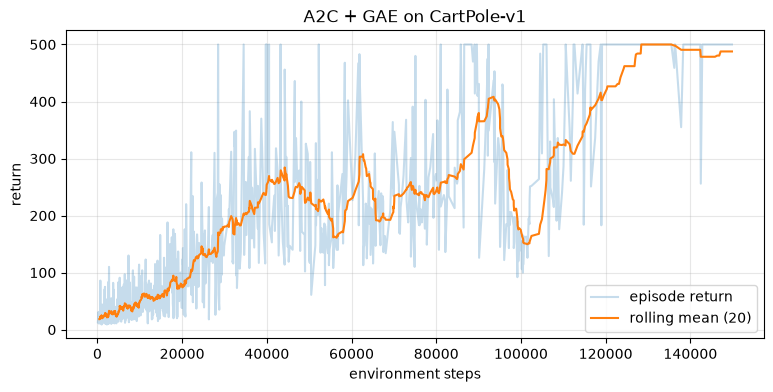

In [12]:
t0 = time.time()
a2c_model, a2c_log = train_a2c(A2CConfig())
print(f"trained in {time.time() - t0:.0f}s")

plt.figure(figsize=(9, 4))
plt.plot(a2c_log["steps"], a2c_log["returns"], alpha=.25, label="episode return")
s = smooth(a2c_log["returns"])
plt.plot(a2c_log["steps"][len(a2c_log["steps"]) - len(s):], s, label="rolling mean (20)")
plt.xlabel("environment steps"); plt.ylabel("return"); plt.title("A2C + GAE on CartPole-v1")
plt.legend(); plt.grid(alpha=.3); plt.show()

A2C typically reaches high returns **much sooner** than REINFORCE. It learns from every rollout instead of every few
episodes. But it can wobble or partly collapse later in training, because one large policy step can undo progress.
Longer rollouts (`n_steps`), a lower learning rate, or PPO's clipped updates (see Next steps) all help.

### The effect of λ

λ sets the bias-variance trade-off of the advantage estimate. This is the policy-gradient version of the n-step
experiment in notebook 1.

λ=0.0  final avg return   66.2
λ=0.9  final avg return  239.7
λ=0.95 final avg return  174.9
λ=1.0  final avg return  185.2


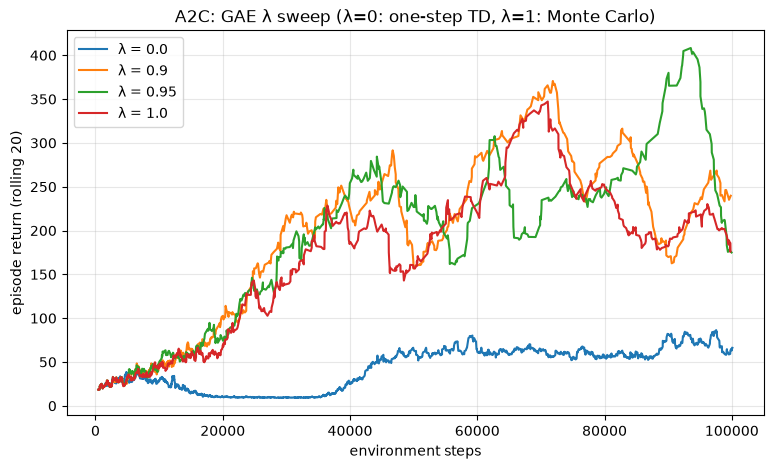

In [13]:
plt.figure(figsize=(9, 5))
for lam in [0.0, 0.9, 0.95, 1.0]:
    _, log = train_a2c(replace(A2CConfig(), gae_lambda=lam, total_steps=100_000), verbose=False)
    s = smooth(log["returns"])
    plt.plot(log["steps"][len(log["steps"]) - len(s):], s, label=f"λ = {lam}")
    print(f"λ={lam:<4} final avg return {np.mean(log['returns'][-20:]):6.1f}")
plt.xlabel("environment steps"); plt.ylabel("episode return (rolling 20)")
plt.title("A2C: GAE λ sweep (λ=0: one-step TD, λ=1: Monte Carlo)"); plt.legend(); plt.grid(alpha=.3); plt.show()

# Part D: A fair comparison over several seeds

Policy-gradient results vary a lot between seeds, so one run per method can be misleading. We train each method on
`SEEDS`, interpolate every learning curve onto a common grid of environment steps, and plot the mean ± standard deviation.
This is the same discipline as validating the tuned DQN on unseen seeds in notebook 4.

This takes roughly 3 seeds × 3 methods × 1–2 minutes on a CPU.

REINFORCE (course)               final return per seed [455.1 139.4 500. ] -> mean 364.8  (14s)
REINFORCE + baseline + entropy   final return per seed [316.1 494.7 500. ] -> mean 436.9  (17s)
A2C + GAE                        final return per seed [487.8 450.8 409.9] -> mean 449.5  (7s)


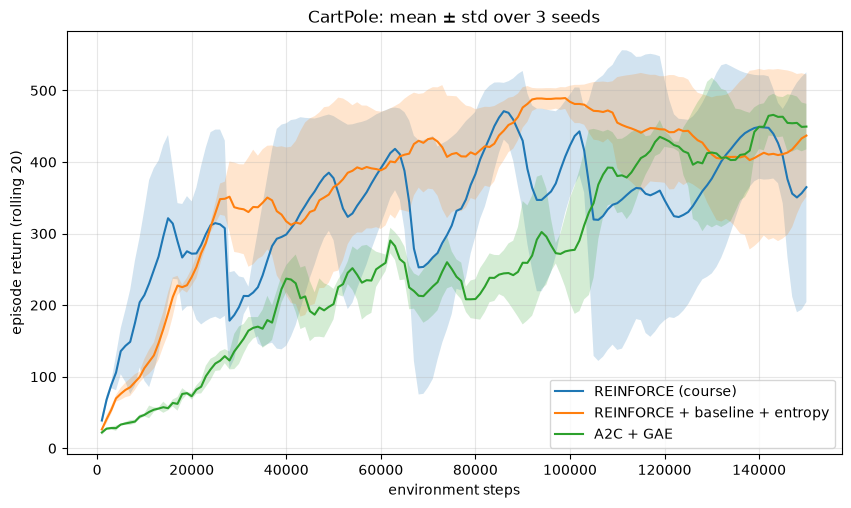

In [14]:
SEEDS = [1, 2, 3]
BUDGET = 150_000
grid = np.linspace(0, BUDGET, 151)

methods = {
    "REINFORCE (course)": lambda seed: train_reinforce(replace(course_cfg, seed=seed, total_steps=BUDGET), verbose=False),
    "REINFORCE + baseline + entropy": lambda seed: train_reinforce(PGConfig(seed=seed, total_steps=BUDGET), verbose=False),
    "A2C + GAE": lambda seed: train_a2c(A2CConfig(seed=seed, total_steps=BUDGET), verbose=False),
}

def curve_on_grid(log, k=20):
    s = smooth(log["returns"], k)
    steps = np.asarray(log["steps"][len(log["steps"]) - len(s):])
    return np.interp(grid, steps, s, left=np.nan)

results = {}
for name, run in methods.items():
    t0 = time.time()
    results[name] = np.array([curve_on_grid(run(seed)[1]) for seed in SEEDS])
    final = results[name][:, -1]
    print(f"{name:<32} final return per seed {np.round(final, 1)} -> mean {np.nanmean(final):.1f}  ({time.time() - t0:.0f}s)")

import warnings
plt.figure(figsize=(10, 5.5))
for name, curves in results.items():
    with warnings.catch_warnings():               # the first grid points have no finished episodes yet (NaN)
        warnings.simplefilter("ignore", RuntimeWarning)
        mean, std = np.nanmean(curves, 0), np.nanstd(curves, 0)
    plt.plot(grid, mean, label=name)
    plt.fill_between(grid, mean - std, mean + std, alpha=.2)
plt.xlabel("environment steps"); plt.ylabel("episode return (rolling 20)")
plt.title(f"CartPole: mean ± std over {len(SEEDS)} seeds"); plt.legend(); plt.grid(alpha=.3); plt.show()

**What to look for**
- **The width of the band** is the variance across seeds. Shrinking it is what baselines, batching and bootstrapping are for.
- **Sample efficiency** is how many environment steps each method needs to reach a return of about 500.
- For reference: DQN in notebook 3 needed about 250k steps with the CleanRL defaults, but it *reuses* every transition
  many times through its replay buffer. Policy-gradient methods are on-policy: each transition is used for one update
  and then thrown away.

# Part E (optional): LunarLander

The course's second task, Pixelcopter, needs the PyGame Learning Environment, which is awkward to install.
**LunarLander** (8-dimensional state, 4 actions) is a good substitute. Landing safely between the flags gives
+100 to +140, crashing gives −100, and firing the engines costs fuel. It counts as **solved at an average of 200**.

The same `train_a2c` works unchanged. Expect it to need on the order of 1–2M steps, roughly 15–40 minutes on a CPU,
and it is sensitive to hyperparameters. It makes a good target for the Ray Tune notebook.
Requires `pip install "gymnasium[box2d]"`.

In [15]:
RUN_LUNAR = False

if RUN_LUNAR:
    lunar_cfg = A2CConfig(env_id="LunarLander-v3", total_steps=1_500_000, n_envs=16, n_steps=8,
                          gamma=0.99, gae_lambda=0.95, lr=7e-4, entropy_coef=0.01, hidden=64)
    t0 = time.time()
    lunar_model, lunar_log = train_a2c(lunar_cfg)
    print(f"trained in {(time.time() - t0) / 60:.1f} min")

    plt.figure(figsize=(9, 4))
    s = smooth(lunar_log["returns"], 50)
    plt.plot(lunar_log["steps"][len(lunar_log["steps"]) - len(s):], s)
    plt.axhline(200, color="k", ls="--", label="solved (200)")
    plt.xlabel("environment steps"); plt.ylabel("episode return (rolling 50)")
    plt.title("A2C + GAE on LunarLander-v3"); plt.legend(); plt.grid(alpha=.3); plt.show()

# Part F: Watch the agent, save it, and what comes next

### Record a video
The course pushes `replay.mp4` to the Hugging Face Hub. This records a local video of an episode.
It needs `pip install imageio imageio-ffmpeg`.

In [16]:
import imageio


def record_video(env_id, act_fn, out_path, fps=30, seed=0, max_steps=1000):
    '''act_fn: maps an observation (np.ndarray) to an action (int).'''
    env = gym.make(env_id, render_mode="rgb_array")
    obs, _ = env.reset(seed=seed)
    frames = [env.render()]
    for _ in range(max_steps):
        obs, _, terminated, truncated, _ = env.step(act_fn(obs))
        frames.append(env.render())
        if terminated or truncated:
            break
    env.close()
    imageio.mimsave(out_path, [np.array(f) for f in frames], fps=fps)
    print(f"saved {len(frames)} frames -> {out_path}")


def greedy_actor_critic(model):
    def act(obs):
        with torch.no_grad():
            return int(model.actor(torch.as_tensor(obs, dtype=torch.float32)).argmax())
    return act


record_video("CartPole-v1", lambda o: cartpole_policy.act(o)[0], "reinforce_cartpole.mp4")
record_video("CartPole-v1", greedy_actor_critic(a2c_model), "a2c_cartpole.mp4")

IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (600, 400) to (608, 400) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).


saved 501 frames -> reinforce_cartpole.mp4


IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (600, 400) to (608, 400) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).


saved 501 frames -> a2c_cartpole.mp4


### Save and load

In [17]:
torch.save({"state_dict": a2c_model.state_dict(), "config": A2CConfig().__dict__}, "a2c_cartpole.pt")

checkpoint = torch.load("a2c_cartpole.pt", weights_only=False)
loaded = ActorCritic(s_size, a_size, checkpoint["config"]["hidden"])
loaded.load_state_dict(checkpoint["state_dict"])
print("loaded model, greedy eval:", evaluate_agent(eval_env, 1000, 10,
      lambda x: F.softmax(loaded.actor(x), dim=-1), greedy=True))

loaded model, greedy eval: (np.float64(500.0), np.float64(0.0))


## Summary

| Method | Advantage estimate | Bias | Variance | Learns before episode ends? |
|---|---|---|---|---|
| REINFORCE | $G_t$ (standardized) | none | very high | no |
| REINFORCE + baseline | $G_t - V(s_t)$ | none | high | no |
| A2C + GAE | $\sum_l (\gamma\lambda)^l \delta_{t+l}$ | some (from V) | lower | **yes** |

- The policy gradient raises the log-probability of actions in proportion to how much better than expected they were.
- Every improvement here is variance reduction: reward-to-go, batching, baselines, bootstrapping, GAE.
- On-policy means no replay buffer: simpler, but less sample-efficient than DQN.

## Next steps

**Continuous actions.** Replace `Categorical` with a Gaussian. Everything else, including the loss, stays the same:
```python
class GaussianActor(nn.Module):
    def __init__(self, obs_dim, act_dim, hidden=64):
        super().__init__()
        self.mu = nn.Sequential(nn.Linear(obs_dim, hidden), nn.Tanh(), nn.Linear(hidden, act_dim))
        self.log_std = nn.Parameter(torch.zeros(act_dim))          # state-independent std, learned

    def dist(self, x):
        return torch.distributions.Normal(self.mu(x), self.log_std.exp())

# log_prob of an action vector = sum over action dimensions:  dist.log_prob(a).sum(-1)
# try it on "Pendulum-v1" or "LunarLanderContinuous-v3"
```

**PPO** (Schulman et al., 2017). The most widely used policy-gradient method, and the natural next notebook.
A2C takes **one** gradient step per rollout, because the data becomes "off-policy" once the policy changes. PPO
reuses each rollout for several epochs of mini-batch updates, and keeps the new policy close to the old one by
**clipping** the probability ratio:

$$\mathcal{L}^{\text{CLIP}} = -\,\mathbb{E}\Big[\min\big(r_t \hat A_t,\; \text{clip}(r_t, 1-\epsilon, 1+\epsilon)\,\hat A_t\big)\Big], \qquad r_t = \frac{\pi_\theta(a_t \mid s_t)}{\pi_{\theta_\text{old}}(a_t \mid s_t)}$$

Starting from `train_a2c`, you need to: store the old log-probs during the rollout, loop over epochs and mini-batches,
and swap the policy loss for the clipped one. CleanRL's `ppo.py` is an excellent single-file reference.

**Tuning.** `train_reinforce` and `train_a2c` return the same kind of `log`, so you can wrap them in the Ray Tune
trainable from notebook 4 and tune `lr`, `gae_lambda`, `entropy_coef` and `n_steps`.

## References
- Hugging Face Deep RL Course, [Unit 4: Policy Gradient with PyTorch](https://huggingface.co/deep-rl-course/unit4/introduction)
- Williams, 1992, *Simple statistical gradient-following algorithms for connectionist reinforcement learning* (REINFORCE)
- Sutton et al., 2000, *Policy Gradient Methods for Reinforcement Learning with Function Approximation*
- Mnih et al., 2016, *Asynchronous Methods for Deep Reinforcement Learning* (A3C/A2C)
- Schulman et al., 2016, *High-Dimensional Continuous Control Using Generalized Advantage Estimation*
- Schulman et al., 2017, *Proximal Policy Optimization Algorithms*
- [OpenAI Spinning Up: Intro to Policy Optimization](https://spinningup.openai.com/en/latest/spinningup/rl_intro3.html)